### Video Object Tracking

Compares two trackers (ByteTrack and BoT-SORT) using the COCO-pretrained YOLO11n on short clips.

- Input videos: `videos_2/` — the 6 optimized videos, each capped to 1 minute
- Trackers: ByteTrack and BoT-SORT
- Annotated frames shown inline and saved to disk
- No CSV files. All numbers are printed in the summary.

Outputs:
- `results/tracking/frames/<video>/<tracker>/`

In [1]:
import time
from pathlib import Path
from collections import Counter
import torch
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

device = 0 if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

PyTorch: 2.14.1+cpu
CUDA available: False
Using device: cpu


### Inputs and outputs

**Input videos:** `videos_2/` — the six optimized videos. Each is capped to the first 60 seconds in this notebook.

**Output:** `results/tracking/frames/<video>/<tracker>/` — annotated JPGs, one per saved frame.

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

VIDEO_DIR = ROOT / "videos_2"
FRAME_DIR = ROOT / "results" / "tracking" / "frames"
FRAME_DIR.mkdir(parents=True, exist_ok=True)

VIDEO_EXTS = {".mp4", ".mov", ".avi", ".mkv"}

video_paths = sorted(
    p for p in VIDEO_DIR.glob("*")
    if p.is_file() and p.suffix.lower() in VIDEO_EXTS
) if VIDEO_DIR.exists() else []

print(f"Video folder:   {VIDEO_DIR.relative_to(ROOT)}  exists={VIDEO_DIR.exists()}")
print(f"Frames folder:  {FRAME_DIR.relative_to(ROOT)}")
print(f"\nFound {len(video_paths)} videos:")
for v in video_paths:
    print(f"  - {v.name}")

if not video_paths:
    raise FileNotFoundError(f"No videos in {VIDEO_DIR}. Put the optimized videos there.")

Video folder:   videos_2  exists=True
Frames folder:  results\tracking\frames

Found 6 videos:
  - optimized_14_43_back_left_cropped.mp4
  - optimized_14_43_back_right_cropped.mp4
  - optimized_14_43_front_cropped.mp4
  - optimized_14_55_back_left_cropped.mp4
  - optimized_14_55_back_right_cropped.mp4
  - optimized_14_55_front_cropped.mp4


### Load pretrained model

`yolo11n.pt` — COCO-pretrained. No gas-cylinder class. This is the reference run.

In [3]:
model = YOLO("yolo11n.pt")
coco_classes = model.names
print(f"Classes: {len(coco_classes)}")
print(f"Has cylinder class: {any('cylinder' in str(v).lower() for v in coco_classes.values())}")

Classes: 80
Has cylinder class: False


### Tracking settings

- Each video is capped to 60 seconds based on its source FPS.
- Trackers: ByteTrack, BoT-SORT.
- 5 annotated frames per video per tracker are saved and shown inline.

In [4]:
MAX_SECONDS = 60
FRAMES_TO_SAVE = 5
TRACKERS = ["bytetrack.yaml", "botsort.yaml"]
CONF = 0.25


def cap_frames(video_path, max_seconds):
    cap = cv2.VideoCapture(str(video_path))
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    limit = min(total, int(fps * max_seconds))
    return fps, total, limit


def sample_indices(limit, n):
    if limit <= 0:
        return []
    step = max(1, limit // n)
    return list(range(0, limit, step))[:n]


print(f"Max seconds per video: {MAX_SECONDS}")
print(f"Frames saved per tracker per video: {FRAMES_TO_SAVE}")
print(f"Trackers: {TRACKERS}")

Max seconds per video: 60
Frames saved per tracker per video: 5
Trackers: ['bytetrack.yaml', 'botsort.yaml']


### Track both trackers on all videos

For each video and each tracker, run `model.track()` on the first 60 seconds. Collect FPS, unique IDs, and top classes. Save 5 tracked frames per tracker.

In [5]:
coco_results = []

for video_path in video_paths:
    fps, total, limit = cap_frames(video_path, MAX_SECONDS)
    print(f"\n{video_path.name}  ({limit}/{total} frames, {fps:.1f} fps)")

    for tracker in TRACKERS:
        tracker_name = tracker.split(".")[0]
        out_dir = FRAME_DIR / video_path.stem / tracker_name
        out_dir.mkdir(parents=True, exist_ok=True)

        t0 = time.time()
        results = model.track(
            source=str(video_path),
            tracker=tracker,
            conf=CONF,
            device=device,
            persist=True,
            stream=True,
            verbose=False,
        )

        frame_count = 0
        unique_ids = set()
        class_counter = Counter()
        saved = 0
        indices_to_save = set(sample_indices(limit, FRAMES_TO_SAVE))

        for r in results:
            if frame_count >= limit:
                break

            boxes = r.boxes
            if boxes is not None and boxes.id is not None:
                ids = boxes.id.cpu().numpy().astype(int)
                cls = boxes.cls.cpu().numpy().astype(int)
                unique_ids.update(ids.tolist())
                for c in cls:
                    class_counter[coco_classes[int(c)]] += 1

            if frame_count in indices_to_save:
                annotated = r.plot()
                cv2.imwrite(str(out_dir / f"frame_{frame_count:04d}.jpg"), annotated)
                saved += 1

            frame_count += 1

        elapsed = time.time() - t0
        fps_run = frame_count / elapsed if elapsed else 0

        coco_results.append({
            "video": video_path.name,
            "tracker": tracker_name,
            "frames": frame_count,
            "seconds": round(elapsed, 1),
            "fps": round(fps_run, 2),
            "unique_ids": len(unique_ids),
            "top_classes": dict(class_counter.most_common(3)),
            "saved": saved,
        })

        print(f"  {tracker_name:10s} frames={frame_count:4d} fps={fps_run:5.2f} ids={len(unique_ids):3d} saved={saved}")


optimized_14_43_back_left_cropped.mp4  (1380/16956 frames, 23.0 fps)
  bytetrack  frames=1380 fps=19.22 ids= 95 saved=5
  botsort    frames=1380 fps=15.23 ids=106 saved=5

optimized_14_43_back_right_cropped.mp4  (1380/16956 frames, 23.0 fps)
  bytetrack  frames=1380 fps=22.34 ids= 36 saved=5
  botsort    frames=1380 fps=17.08 ids= 42 saved=5

optimized_14_43_front_cropped.mp4  (1380/16956 frames, 23.0 fps)
  bytetrack  frames=1380 fps=22.83 ids= 27 saved=5
  botsort    frames=1380 fps=17.21 ids= 29 saved=5

optimized_14_55_back_left_cropped.mp4  (1380/10050 frames, 23.0 fps)
  bytetrack  frames=1380 fps=22.05 ids= 42 saved=5
  botsort    frames=1380 fps=17.76 ids= 44 saved=5

optimized_14_55_back_right_cropped.mp4  (1380/10050 frames, 23.0 fps)
  bytetrack  frames=1380 fps=22.53 ids= 91 saved=5
  botsort    frames=1380 fps=17.83 ids= 91 saved=5

optimized_14_55_front_cropped.mp4  (1380/10050 frames, 23.0 fps)
  bytetrack  frames=1380 fps=23.36 ids= 32 saved=5
  botsort    frames=1380 

### Tracked frames (inline)

One representative frame per tracker from the first video. All saved frames are on disk in `results/tracking/frames/`.

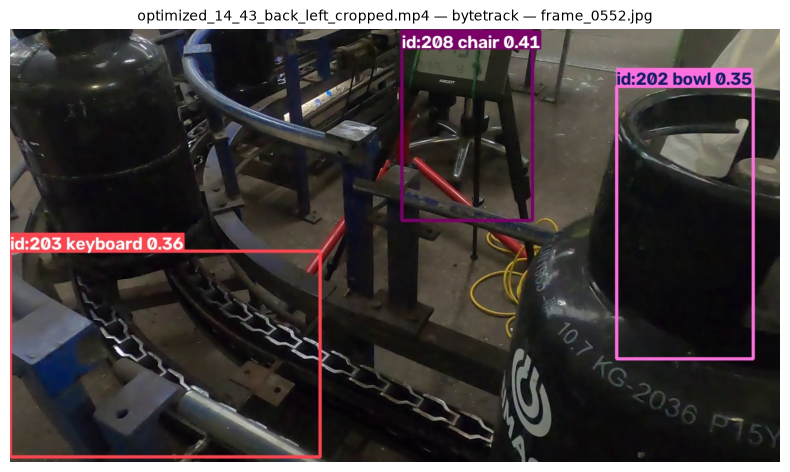

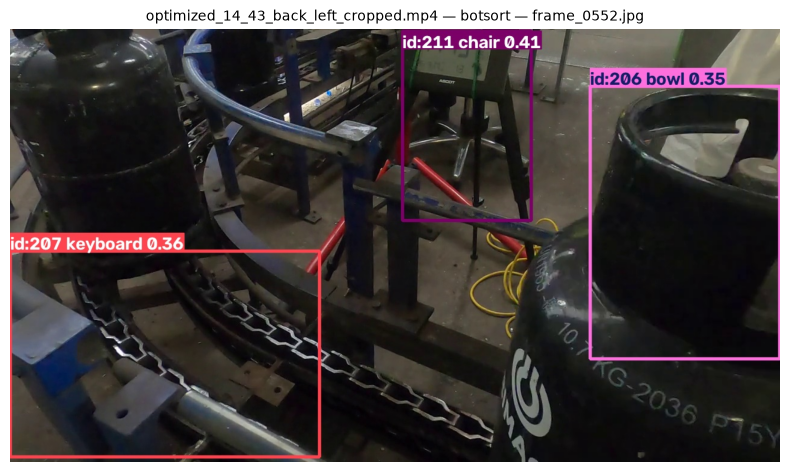

In [6]:
first_video = video_paths[0]

for tracker in TRACKERS:
    tracker_name = tracker.split(".")[0]
    folder = FRAME_DIR / first_video.stem / tracker_name
    files = sorted(folder.glob("*.jpg"))
    if not files:
        print(f"[skip] no frames in {folder.relative_to(ROOT)}")
        continue

    show = files[len(files) // 2]
    img = cv2.cvtColor(cv2.imread(str(show)), cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(f"{first_video.name} — {tracker_name} — {show.name}", fontsize=10)
    plt.tight_layout()
    plt.show()

### Summary

In [7]:
print("=" * 70)
print("INPUTS AND OUTPUTS")
print("=" * 70)
print(f"Input folder:            {VIDEO_DIR.relative_to(ROOT)}")
print(f"Videos used:             {len(video_paths)}")
print(f"Max seconds per video:   {MAX_SECONDS}")
print(f"Frames saved to:         {FRAME_DIR.relative_to(ROOT)}")

print("\n" + "=" * 70)
print("TRACKING SUMMARY")
print("=" * 70)
for tracker_name in ["bytetrack", "botsort"]:
    rows = [r for r in coco_results if r["tracker"] == tracker_name]
    if not rows:
        continue
    avg_fps = sum(r["fps"] for r in rows) / len(rows)
    avg_ids = sum(r["unique_ids"] for r in rows) / len(rows)
    total_frames = sum(r["frames"] for r in rows)
    print(f"\n{tracker_name.upper()}")
    print(f"  videos:        {len(rows)}")
    print(f"  avg FPS:       {avg_fps:.2f}")
    print(f"  avg unique ID: {avg_ids:.1f}")
    print(f"  total frames:  {total_frames}")

print("\nPer-video breakdown:")
for r in coco_results:
    print(f"  {r['video']:45s} {r['tracker']:10s} frames={r['frames']:4d} fps={r['fps']:5.2f} ids={r['unique_ids']:3d} top={r['top_classes']}")

print("\n" + "=" * 70)
print("Saved frames")
print("=" * 70)
print(f"  {FRAME_DIR.relative_to(ROOT)}/<video>/<tracker>/")

INPUTS AND OUTPUTS
Input folder:            videos_2
Videos used:             6
Max seconds per video:   60
Frames saved to:         results\tracking\frames

TRACKING SUMMARY

BYTETRACK
  videos:        6
  avg FPS:       22.05
  avg unique ID: 53.8
  total frames:  8280

BOTSORT
  videos:        6
  avg FPS:       16.94
  avg unique ID: 56.8
  total frames:  8280

Per-video breakdown:
  optimized_14_43_back_left_cropped.mp4         bytetrack  frames=1380 fps=19.22 ids= 95 top={'person': 923, 'vase': 564, 'chair': 480}
  optimized_14_43_back_left_cropped.mp4         botsort    frames=1380 fps=15.23 ids=106 top={'person': 923, 'vase': 572, 'chair': 474}
  optimized_14_43_back_right_cropped.mp4        bytetrack  frames=1380 fps=22.34 ids= 36 top={'vase': 637, 'person': 270, 'cake': 146}
  optimized_14_43_back_right_cropped.mp4        botsort    frames=1380 fps=17.08 ids= 42 top={'vase': 641, 'person': 260, 'cake': 144}
  optimized_14_43_front_cropped.mp4             bytetrack  frames=138